# Análisis estadístico del experimento (tesis, Cap. III y V)

Ruta **convencional** (proximidad sucesiva geográfica, sin tráfico) contra ruta **optimizada** (algoritmo genético con tráfico por franja), sobre el mismo conjunto de puntos y las mismas condiciones de la vía.

- 3 escenarios × 10 repeticiones (4 pico matutino, 3 valle, 3 pico vespertino) = 30 pares.
- Normalidad de las diferencias: **Shapiro-Wilk**. Si son normales, **t pareada**; si no, **Wilcoxon** de rangos con signo (unilateral: la optimizada es menor).
- Tamaño del efecto: **d de Cohen** pareada. Nivel de significancia **α = 0.05**.
- Regla de decisión de la tesis: se rechaza H0 si **p < 0.05 y la reducción media de distancia es ≥ 15 %**.

Datos: `matriz_comparativa.csv`, generado por `python manage.py run_thesis_experiment` sobre el grafo real (aristas y tráfico de Google Routes API). En Colab, sube el CSV a la sesión.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

ALFA = 0.05
candidatos = [Path('matriz_comparativa.csv'), Path('../../docs/Capitulo V/resultados/matriz_comparativa.csv')]
ruta = next(p for p in candidatos if p.exists())
df = pd.read_csv(ruta, encoding='utf-8-sig')
print(ruta, df.shape, '| fuente:', df['fuente_datos'].iloc[0])
df[['escenario', 'repeticion', 'franja', 'convencional_km', 'optimizada_km', 'reduccion_km_pct',
    'convencional_min', 'optimizada_min', 'reduccion_min_pct', 'tiempo_respuesta_s']].head(10)

..\..\docs\Capitulo V\resultados\matriz_comparativa.csv (30, 23) | fuente: edges=google;traffic=google_routes


,escenario,repeticion,franja,convencional_km,optimizada_km,reduccion_km_pct,convencional_min,optimizada_min,reduccion_min_pct,tiempo_respuesta_s
0,normal,1,pico matutino,663.95,582.21,12.31,1258,1027,18.35,0.340
1,normal,2,pico matutino,642.32,645.32,-0.47,959,952,0.75,0.210
2,normal,3,pico matutino,1225.46,1163.84,5.03,1662,1539,7.38,0.207
3,normal,4,pico matutino,700.49,649.11,7.33,1240,1133,8.59,0.439
4,normal,5,valle,654.92,624.80,4.60,1010,904,10.46,0.175
5,normal,6,valle,1036.33,1036.47,-0.01,1416,1392,1.70,0.243
6,normal,7,valle,761.21,652.21,14.32,1406,1144,18.65,0.333
7,normal,8,pico vespertino,566.02,569.03,-0.53,868,858,1.13,0.202
8,normal,9,pico vespertino,1171.80,1064.19,9.18,1509,1367,9.40,0.214
9,normal,10,pico vespertino,634.94,551.68,13.11,1280,993,22.48,0.604


## Estadística descriptiva por escenario (media y desviación estándar)

In [2]:
cols = ['convencional_km', 'optimizada_km', 'reduccion_km_pct', 'convencional_min', 'optimizada_min',
        'reduccion_min_pct', 'tiempo_respuesta_s']
display(df.groupby('escenario_nombre')[cols].agg(['mean', 'std']).round(2))
display(df[cols].agg(['mean', 'std']).round(2))

convencional_km         optimizada_km  \
                                               mean     std          mean   
escenario_nombre                                                            
Cierre de vía con ruta alternativa           903.12  344.68        845.52   
Congestionamiento en ruta principal          805.74  243.26        837.12   
Tráfico normal                               805.74  243.26        753.89   

                                            reduccion_km_pct         \
                                        std             mean    std   
escenario_nombre                                                      
Cierre de vía con ruta alternativa   301.86             5.67   4.93   
Congestionamiento en ruta principal  220.18            -5.25  10.92   
Tráfico normal                       235.35             6.49   5.70   

                                    convencional_min         optimizada_min  \
                                                mean     std           mean   
escenario_nombre                                                              
Cierre de vía con ruta alternativa            1408.6  371.64         1245.7   
Congestionamiento en ruta principal           2271.4  522.59         1779.5   
Tráfico normal                                1260.8  253.16         1130.9   

                                            reduccion_min_pct         \
                                        std              mean    std   
escenario_nombre                                                       
Cierre de vía con ruta alternativa   314.30             10.93   7.67   
Congestionamiento en ruta principal  368.50             20.35  11.25   
Tráfico normal                       230.56              9.89   7.77   

                                    tiempo_respuesta_s        
                                                  mean   std  
escenario_nombre                                              
Cierre de vía con ruta alternativa                0.24  0.08  
Congestionamiento en ruta principal               0.20  0.08  
Tráfico normal                                    0.30  0.14

,convencional_km,optimizada_km,reduccion_km_pct,convencional_min,optimizada_min,reduccion_min_pct,tiempo_respuesta_s
mean,838.20,812.18,2.30,1646.93,1385.37,13.72,0.25
std,275.28,249.56,9.18,594.12,414.63,9.96,0.10


## Pruebas de hipótesis

In [3]:
def prueba_pareada(conv, opt):
    conv, opt = np.asarray(conv, float), np.asarray(opt, float)
    d = conv - opt
    sh = stats.shapiro(d)
    normal = sh.pvalue > ALFA
    if normal:
        nombre, p = 't pareada', stats.ttest_rel(conv, opt, alternative='greater').pvalue
    else:
        nombre, p = 'Wilcoxon', stats.wilcoxon(conv, opt, alternative='greater').pvalue
    reduccion = np.mean((conv - opt) / conv * 100)
    return {'n': len(d), 'shapiro_p': round(sh.pvalue, 5), 'normal': normal, 'prueba': nombre,
            'p_valor': p, 'd_cohen': round(d.mean() / d.std(ddof=1), 3), 'reduccion_media_%': round(reduccion, 2),
            'significativo': p < ALFA}

filas = []
for nombre, sub in [('Total', df), *df.groupby('escenario_nombre')]:
    for metrica, c, o in [('Distancia (km)', 'convencional_km', 'optimizada_km'),
                          ('Tiempo (min)', 'convencional_min_exacto', 'optimizada_min_exacto')]:
        filas.append({'escenario': nombre, 'metrica': metrica, **prueba_pareada(sub[c], sub[o])})
pruebas = pd.DataFrame(filas)
pruebas

,escenario,metrica,n,shapiro_p,normal,prueba,p_valor,d_cohen,reduccion_media_%,significativo
0,Total,Distancia (km),30,0.27721,True,t pareada,3.029914e-02,0.356,2.30,True
1,Total,Tiempo (min),30,0.00002,False,Wilcoxon,9.313226e-10,0.973,13.72,True
2,Cierre de vía con ruta alternativa,Distancia (km),10,0.05007,True,t pareada,1.067064e-02,0.880,5.67,True
3,Cierre de vía con ruta alternativa,Tiempo (min),10,0.44671,True,t pareada,1.126697e-03,1.333,10.93,True
4,Congestionamiento en ruta principal,Distancia (km),10,0.09411,True,t pareada,8.944439e-01,-0.426,-5.25,False
5,Congestionamiento en ruta principal,Tiempo (min),10,0.05390,True,t pareada,7.190178e-04,1.431,20.35,True
6,Tráfico normal,Distancia (km),10,0.19057,True,t pareada,2.406672e-03,1.175,6.49,True
7,Tráfico normal,Tiempo (min),10,0.27892,True,t pareada,1.546188e-03,1.266,9.89,True


## Decisión sobre H0 y metas de la tesis

In [4]:
km = pruebas[(pruebas.escenario == 'Total') & (pruebas.metrica == 'Distancia (km)')].iloc[0]
mins = pruebas[(pruebas.escenario == 'Total') & (pruebas.metrica == 'Tiempo (min)')].iloc[0]
cierre = df[df['escenario'] == 'cierre']
exito = cierre['ruta_alterna_exitosa'].astype(str).str.lower().eq('true').mean() * 100
resp_max = df['tiempo_respuesta_s'].max()
h0 = bool(km['significativo'] and km['reduccion_media_%'] >= 15)
metas = pd.DataFrame([
    ('Reducción de distancia ≥ 15 %', f"{km['reduccion_media_%']:.2f} %", km['reduccion_media_%'] >= 15),
    ('Reducción de tiempo ≥ 20 %', f"{mins['reduccion_media_%']:.2f} %", mins['reduccion_media_%'] >= 20),
    ('Rutas alternativas exitosas > 90 %', f'{exito:.1f} %', exito > 90),
    ('Tiempo de respuesta < 30 s', f'{resp_max:.2f} s (máx.)', resp_max < 30),
], columns=['meta', 'resultado', 'cumple'])
display(metas)
print('H0 (distancia) rechazada:', h0, '| regla: p < 0.05 y reducción media ≥ 15 %')

,meta,resultado,cumple
0,Reducción de distancia ≥ 15 %,2.30 %,False
1,Reducción de tiempo ≥ 20 %,13.72 %,False
2,Rutas alternativas exitosas > 90 %,100.0 %,True
3,Tiempo de respuesta < 30 s,0.60 s (máx.),True


H0 (distancia) rechazada: False | regla: p < 0.05 y reducción media ≥ 15 %


## Gráficas

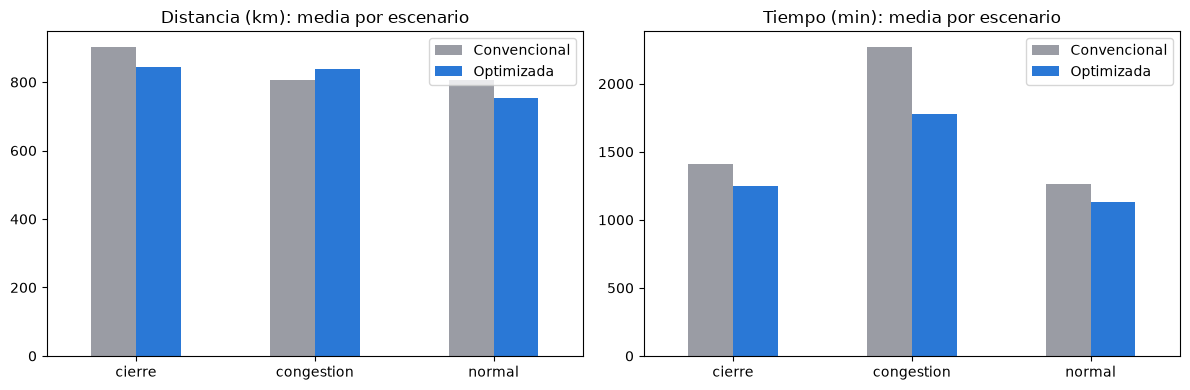

C:\Users\Julio Ticas\AppData\Local\Temp\ipykernel_15300\1133141244.py:10: UserWarning: To output multiple subplots, the figure containing the passed axes is being cleared.
  df.boxplot(column=['reduccion_km_pct', 'reduccion_min_pct'], by='escenario', ax=ax)


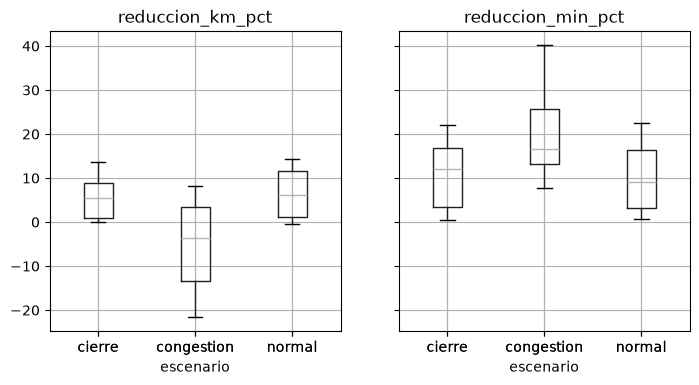

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (c, o, titulo) in zip(axes, [('convencional_km', 'optimizada_km', 'Distancia (km)'),
                                      ('convencional_min', 'optimizada_min', 'Tiempo (min)')]):
    g = df.groupby('escenario')[[c, o]].mean()
    g.plot.bar(ax=ax, color=['#9a9ca4', '#2a78d6'], rot=0)
    ax.set_title(f'{titulo}: media por escenario'); ax.set_xlabel(''); ax.legend(['Convencional', 'Optimizada'])
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
df.boxplot(column=['reduccion_km_pct', 'reduccion_min_pct'], by='escenario', ax=ax)
ax.axhline(15, ls='--', c='#eb6834', lw=1); ax.axhline(20, ls=':', c='#eb6834', lw=1)
plt.suptitle(''); ax.set_title('Reducción por escenario (%) · metas 15 % y 20 %'); plt.show()

## Genético contra OR-Tools (línea base)

In [6]:
base = next((p for p in [Path('genetico_vs_ortools.csv'), Path('../../docs/Capitulo V/resultados/genetico_vs_ortools.csv')] if p.exists()), None)
if base is not None:
    b = pd.read_csv(base, encoding='utf-8-sig')
    display(b[['genetico_min', 'ortools_min', 'diferencia_pct', 'genetico_ms', 'ortools_ms']].describe().round(3))
    print('Instancias en que el genético iguala o mejora a OR-Tools:', int((b['diferencia_pct'] <= 1e-6).sum()), 'de', len(b))

,genetico_min,ortools_min,diferencia_pct,genetico_ms,ortools_ms
count,30.000,30.000,30.0,30.000,30.000
mean,1434.008,1434.008,0.0,145.767,10002.337
std,422.721,422.721,0.0,49.124,2.850
min,925.050,925.050,0.0,85.700,10001.000
25%,1103.071,1103.071,0.0,112.350,10001.525
50%,1434.492,1434.492,0.0,125.400,10001.800
75%,1699.883,1699.883,-0.0,158.575,10002.050
max,2485.900,2485.900,0.0,291.800,10017.100


Instancias en que el genético iguala o mejora a OR-Tools: 30 de 30
